In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from huggingface_hub import login
login()

In [3]:
!pip -q install -U transformers onnx

import os, json, time, random, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import sigmoid_focal_loss
from torch.utils.flop_counter import FlopCounterMode
from transformers import AutoModel

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
LOCAL_PROCESSED = "/content/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{BASE_DIR}/predictions"
RESULTS_CSV = f"{RESULTS_DIR}/results_dino.csv"
for d in [LOCAL_PROCESSED, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, PREDICTIONS_DIR]:
	os.makedirs(d, exist_ok=True)

W, H = 640, 224
DS = {'culane': {'w': 1640, 'h': 590, 'crop': 236}, 'bdd': {'w': 1280, 'h': 720, 'crop': 302}}
LINE_WIDTH = {'culane': 30, 'bdd': 23}
SPLIT_DS = {'train': 'culane', 'val': 'culane', 'test_culane': 'culane', 'test_bdd': 'bdd'}
DINO_MODELS = {'dinov3_vits16': 'facebook/dinov3-vits16-pretrain-lvd1689m',
               'dinov3_convnext_tiny': 'facebook/dinov3-convnext-tiny-pretrain-lvd1689m'}

In [4]:
def load(name):
	src = f"{PROCESSED_DIR}/{name}"
	dst = f"{LOCAL_PROCESSED}/{name}"
	if not os.path.exists(f"{dst}/meta.csv"):
		shutil.copytree(src, dst, dirs_exist_ok=True)
	images = np.load(f"{dst}/images.npy", mmap_mode='r')
	lanes = np.load(f"{dst}/lanes.npy")
	meta = pd.read_csv(f"{dst}/meta.csv")
	return images, lanes, meta

def resample(x, y):
	order = np.argsort(y)
	x = x[order]
	y = y[order]
	rows = np.arange(H)
	out = np.full(H, np.nan, np.float32)
	inside = (rows >= y[0]) & (rows <= y[-1])
	out[inside] = np.interp(rows[inside], y, x)
	return out

def to_orig(lanes, ds):
	c = DS[ds]
	x = lanes * c['w'] / W
	y = np.arange(H) * (c['h'] - c['crop']) / H + c['crop']
	return x, y

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
	img = np.array(img)
	for k in range(2):
		rows = np.where(np.isfinite(lanes[k]))[0]
		if len(rows) > 1:
			points = np.stack([lanes[k][rows], rows], 1).round().astype(np.int32)
			cv2.polylines(img, [points], False, colors[k], thickness)
	return img

def show_pred(images, gt, pred, idx, title, path=None):
	n_rows = (len(idx) + 2) // 3
	plt.figure(figsize=(18, 2.6 * n_rows))
	for j in range(len(idx)):
		img = draw(images[idx[j]], gt[idx[j]], thickness=6)
		img = draw(img, pred[j], colors=((255, 255, 0), (0, 255, 255)))
		plt.subplot(n_rows, 3, j + 1)
		plt.imshow(img)
		plt.axis('off')
	plt.suptitle(title)
	plt.tight_layout()
	if path:
		plt.savefig(path, dpi=120, bbox_inches='tight')
	plt.show()

def log_result(row):
	row['time'] = time.strftime('%Y-%m-%d %H:%M')
	table = pd.DataFrame([row])
	if os.path.exists(RESULTS_CSV):
		table = pd.concat([pd.read_csv(RESULTS_CSV), table], ignore_index=True)
	table.to_csv(RESULTS_CSV, index=False)

def save_predictions(run, split, lanes, conf, sigma):
	os.makedirs(f"{PREDICTIONS_DIR}/{run}", exist_ok=True)
	np.savez_compressed(f"{PREDICTIONS_DIR}/{run}/{split}.npz", lanes=lanes, conf=conf, sigma=sigma)

In [5]:
def lane_mask(x, ds):
	c = DS[ds]
	xo, yo = to_orig(x, ds)
	mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
	rows = np.where(np.isfinite(xo))[0]
	if len(rows) > 1:
		points = np.stack([xo[rows], yo[rows] - c['crop']], 1).round().astype(np.int32)
		cv2.polylines(mask, [points], False, 1, LINE_WIDTH[ds])
	return mask

def iou(a, b):
	union = np.count_nonzero(a | b)
	if union == 0:
		return 0.0
	return np.count_nonzero(a & b) / union

def frame_ious(pred, gt, ds):
	pred_masks = []
	gt_masks = []
	for k in range(2):
		if np.isfinite(pred[k]).sum() > 1:
			pred_masks.append(lane_mask(pred[k], ds))
		else:
			pred_masks.append(None)
		if np.isfinite(gt[k]).sum() > 1:
			gt_masks.append(lane_mask(gt[k], ds))
		else:
			gt_masks.append(None)
	side = []
	for k in range(2):
		if pred_masks[k] is not None and gt_masks[k] is not None:
			side.append(iou(pred_masks[k], gt_masks[k]))
		else:
			side.append(np.nan)
	P = [m for m in pred_masks if m is not None]
	G = [m for m in gt_masks if m is not None]
	matched = []
	if len(P) > 0 and len(G) > 0:
		M = np.zeros((len(P), len(G)))
		for a in range(len(P)):
			for b in range(len(G)):
				M[a, b] = iou(P[a], G[b])
		r, c = linear_sum_assignment(-M)
		matched = list(M[r, c])
	return {'n_pred': len(P), 'n_gt': len(G), 'matched': matched, 'side': side,
	        'pred_on': [m is not None for m in pred_masks], 'gt_on': [m is not None for m in gt_masks]}

def prf(tp, fp, fn):
	if tp + fp + fn == 0:
		return np.nan, np.nan, np.nan
	p = tp / (tp + fp) if tp + fp > 0 else 0.0
	r = tp / (tp + fn) if tp + fn > 0 else 0.0
	f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
	return p, r, f1

def score(records, thr):
	tp, n_pred, n_gt = 0, 0, 0
	for r in records:
		tp += sum(m > thr for m in r['matched'])
		n_pred += r['n_pred']
		n_gt += r['n_gt']
	p, rec, f1 = prf(tp, n_pred - tp, n_gt - tp)
	out = {'precision': p, 'recall': rec, 'f1': f1, 'fp': n_pred - tp}
	for k, name in enumerate(['left', 'right']):
		tp_side, pred_side, gt_side = 0, 0, 0
		for r in records:
			tp_side += r['side'][k] > thr
			pred_side += r['pred_on'][k]
			gt_side += r['gt_on'][k]
		out[f'f1_{name}'] = prf(tp_side, pred_side - tp_side, gt_side - tp_side)[2]
	return out

def evaluate(pred_lanes, split, idx=None):
	_, gt_lanes, meta = load(split)
	ds = SPLIT_DS[split]
	if idx is None:
		idx = np.arange(len(meta))
	with ThreadPoolExecutor(8) as pool:
		records = list(pool.map(frame_ious, pred_lanes, gt_lanes[idx], [ds] * len(idx)))
	conditions = meta.condition.values[idx]
	rows = []
	for c in ['all'] + sorted(set(conditions)):
		rec = [records[j] for j in range(len(records)) if c == 'all' or conditions[j] == c]
		row = {'condition': c, 'n': len(rec)}
		row.update(score(rec, 0.5))
		row['f1@0.7'] = score(rec, 0.7)['f1']
		rows.append(row)
	return pd.DataFrame(rows).set_index('condition'), records

In [6]:
N_ROWS, N_CELLS = 36, 120
ROWS = np.linspace(10, H - 1, N_ROWS).astype(int)
X_MIN, X_MAX = -0.25 * W, 1.25 * W
CELL = (X_MAX - X_MIN) / N_CELLS
MIN_ROWS = 4
BATCH, LR = 32, 4e-4
FROZEN_EPOCHS, FINETUNE_EPOCHS = 15, 30
LOSS_WEIGHTS = {'position': 1.0, 'l1': 0.2, 'exist': 5.0, 'aux': 0.5, 'distill': 1.0}
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def augment(img, lanes):
	if random.random() < 0.5:
		img = img[:, ::-1].copy()
		lanes = (W - 1 - lanes)[::-1].copy()
	if random.random() < 0.7:
		M = cv2.getRotationMatrix2D((W / 2, H), random.uniform(-4, 4), random.uniform(0.9, 1.1))
		M[0, 2] += random.uniform(-0.05, 0.05) * W
		M[1, 2] += random.uniform(-0.05, 0.05) * H
		img = cv2.warpAffine(img, M, (W, H))
		for k in range(2):
			rows = np.where(np.isfinite(lanes[k]))[0]
			if len(rows) > 1:
				x_new = M[0, 0] * lanes[k][rows] + M[0, 1] * rows + M[0, 2]
				y_new = M[1, 0] * lanes[k][rows] + M[1, 1] * rows + M[1, 2]
				lanes[k] = resample(x_new, y_new)
	img = img.astype(np.float32) * random.uniform(0.7, 1.3) + random.uniform(-30, 30)
	img = np.clip(img, 0, 255)
	if random.random() < 0.2:
		img = 255 * (img / 255) ** random.uniform(1.8, 2.8)
	elif random.random() < 0.3:
		img = 255 * (img / 255) ** random.uniform(0.7, 1.4)
	if random.random() < 0.2:
		img = cv2.GaussianBlur(img, (5, 5), 0)
	if random.random() < 0.2:
		img = img + np.random.normal(0, 8, img.shape)
	img = np.clip(img, 0, 255).astype(np.uint8)
	return img, lanes

class LaneDataset(Dataset):
	def __init__(self, split, train=False, idx=None):
		self.images, self.lanes, meta = load(split)
		if idx is None:
			idx = np.arange(len(meta))
		self.idx = idx
		self.train = train

	def __len__(self):
		return len(self.idx)

	def __getitem__(self, j):
		i = self.idx[j]
		img = np.array(self.images[i])
		lanes = self.lanes[i].copy()
		if self.train:
			img, lanes = augment(img, lanes)
		img = (img / 255.0 - MEAN) / STD
		img = torch.tensor(img.transpose(2, 0, 1), dtype=torch.float32)

		x = lanes[:, ROWS]
		present = np.isfinite(x) & (x >= X_MIN) & (x < X_MAX)
		target = (np.nan_to_num(x) - X_MIN) / CELL - 0.5
		target = np.clip(target, 0, N_CELLS - 1)

		mask = np.zeros((H // 16, W // 16), np.uint8)
		for k in range(2):
			rows = np.where(np.isfinite(lanes[k]))[0]
			if len(rows) > 1:
				points = np.stack([lanes[k][rows] / 16, rows / 16], 1).round().astype(np.int32)
				cv2.polylines(mask, [points], False, k + 1, 1)

		return img, torch.tensor(target, dtype=torch.float32), torch.tensor(present), torch.tensor(mask, dtype=torch.long)

In [7]:
class Backbone(nn.Module):
	def __init__(self, name):
		super().__init__()
		self.name = name
		if name == 'resnet18' or name == 'resnet18_l3':
			r = torchvision.models.resnet18(weights='IMAGENET1K_V1')
			self.stage3 = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3)
			self.stage4 = r.layer4
		else:
			self.model = AutoModel.from_pretrained(DINO_MODELS[name])

	def forward(self, x):
		if self.name == 'resnet18':
			f3 = self.stage3(x)
			return [f3, self.stage4(f3)]
		if self.name == 'resnet18_l3':
			return [self.stage3(x)]
		if self.name == 'dinov3_convnext_tiny':
			hidden = self.model(pixel_values=x, output_hidden_states=True).hidden_states
			return [hidden[-2], hidden[-1]]
		tokens = self.model(pixel_values=x).last_hidden_state
		h = x.shape[2] // 16
		w = x.shape[3] // 16
		tokens = tokens[:, -h * w:]
		return [tokens.transpose(1, 2).reshape(x.shape[0], -1, h, w)]

class LaneNet(nn.Module):
	def __init__(self, backbone_name, channels=96):
		super().__init__()
		self.backbone = Backbone(backbone_name)
		self.backbone.eval()
		with torch.no_grad():
			maps = self.backbone(torch.zeros(1, 3, H, W))
		self.reduce = nn.ModuleList()
		for m in maps:
			self.reduce.append(nn.Conv2d(m.shape[1], channels, 1))
		self.row_embedding = nn.Parameter(torch.zeros(1, channels, N_ROWS, 1))
		features_per_row = channels * maps[0].shape[3]
		self.position_head = nn.Linear(features_per_row, 2 * N_CELLS)
		self.exist_head = nn.Linear(features_per_row, 2)
		self.aux_head = nn.Sequential(nn.Conv2d(channels, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 3, 1))

	def forward(self, x):
		maps = self.backbone(x)
		f = self.reduce[0](maps[0])
		if len(maps) > 1:
			f = f + F.interpolate(self.reduce[1](maps[1]), size=f.shape[2:], mode='bilinear')
		aux = self.aux_head(f)
		r = F.interpolate(f, size=(N_ROWS, f.shape[3]), mode='bilinear')
		r = F.relu(r + self.row_embedding)
		r = r.permute(0, 2, 1, 3).flatten(2)
		position = self.position_head(r).reshape(-1, N_ROWS, 2, N_CELLS).transpose(1, 2)
		exist = self.exist_head(r).transpose(1, 2)
		if self.training:
			return position, exist, aux
		return position, exist

for name in DINO_MODELS:
	test_model = LaneNet(name)
	print(name, 'loaded,', round(sum(p.numel() for p in test_model.parameters()) / 1e6, 1), 'M parameters')
del test_model

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

dinov3_vits16 loaded, 22.6 M parameters


config.json:   0%|          | 0.00/446 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  111MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/180 [00:00<?, ?it/s]

dinov3_convnext_tiny loaded, 28.9 M parameters


In [8]:
def dice_loss(logits, mask):
	prob = logits.softmax(1)[:, 1:]
	target = F.one_hot(mask, 3).permute(0, 3, 1, 2)[:, 1:].float()
	overlap = (prob * target).sum()
	total = prob.sum() + target.sum()
	return 1 - (2 * overlap + 1) / (total + 1)

def compute_loss(position, exist, aux, target, present, mask):
	present = present.float()
	n = present.sum().clamp(min=1)

	left = target.floor().long().clamp(0, N_CELLS - 2)
	w_right = target - left
	soft_target = (1 - w_right)[..., None] * F.one_hot(left, N_CELLS) + w_right[..., None] * F.one_hot(left + 1, N_CELLS)
	log_prob = F.log_softmax(position, dim=-1)
	position_loss = (-(soft_target * log_prob).sum(-1) * present).sum() / n

	cells = torch.arange(N_CELLS, device=position.device)
	expected = (position.softmax(-1) * cells).sum(-1)
	l1_loss = ((expected - target).abs() * present).sum() / n

	exist_loss = sigmoid_focal_loss(exist, present, alpha=-1, gamma=2, reduction='mean')

	aux = F.interpolate(aux, size=mask.shape[1:], mode='bilinear')
	aux_loss = F.cross_entropy(aux, mask) + dice_loss(aux, mask)

	w = LOSS_WEIGHTS
	return w['position'] * position_loss + w['l1'] * l1_loss + w['exist'] * exist_loss + w['aux'] * aux_loss

def distill_loss(position, exist, teacher_position, teacher_exist, T=2.0):
	teacher_prob = (teacher_position / T).softmax(-1)
	student_log_prob = (position / T).log_softmax(-1)
	kl = (teacher_prob * (teacher_prob.clamp_min(1e-8).log() - student_log_prob)).sum(-1)
	weight = teacher_exist.sigmoid()
	kl_loss = (kl * weight).sum() / weight.sum().clamp(min=1) * T * T
	exist_loss = F.binary_cross_entropy_with_logits(exist, teacher_exist.sigmoid())
	return kl_loss + exist_loss

In [9]:
@torch.no_grad()
def predict_raw(model, split, idx=None):
	model.eval()
	loader = DataLoader(LaneDataset(split, False, idx), batch_size=64, num_workers=8)
	cells = torch.arange(N_CELLS).cuda()
	means, spreads, probs = [], [], []
	for img, target, present, mask in loader:
		with torch.autocast('cuda', dtype=torch.bfloat16):
			position, exist = model(img.cuda())
		p = position.float().softmax(-1)
		mean = (p * cells).sum(-1)
		spread = ((p * (cells - mean[..., None]) ** 2).sum(-1)).sqrt()
		means.append(mean.cpu().numpy())
		spreads.append(spread.cpu().numpy())
		probs.append(exist.float().sigmoid().cpu().numpy())
	return np.concatenate(means), np.concatenate(spreads), np.concatenate(probs)

def to_lanes(raw, threshold=0.5):
	mean, spread, prob = raw
	xs = X_MIN + (mean + 0.5) * CELL
	sig = spread * CELL
	n = len(mean)
	lanes = np.full((n, 2, H), np.nan, np.float32)
	sigma = np.full((n, 2, H), np.nan, np.float32)
	conf = np.zeros((n, 2), np.float32)
	for i in range(n):
		for k in range(2):
			on = prob[i, k] > threshold
			if on.sum() >= MIN_ROWS:
				lanes[i, k] = resample(xs[i, k, on], ROWS[on])
				sigma[i, k] = resample(sig[i, k, on], ROWS[on])
				conf[i, k] = prob[i, k, on].mean()
	return lanes, conf, sigma

def train(run, backbone, epochs, freeze=False, teacher=None, train_idx=None, val_idx=None):
	torch.manual_seed(SEED)
	model = LaneNet(backbone).cuda()

	head_params = []
	backbone_params = []
	for name, p in model.named_parameters():
		if name.startswith('backbone'):
			backbone_params.append(p)
		else:
			head_params.append(p)
	if freeze:
		for p in backbone_params:
			p.requires_grad = False
		groups = [{'params': head_params, 'lr': LR}]
	else:
		groups = [{'params': head_params, 'lr': LR}, {'params': backbone_params, 'lr': LR / 10}]
	max_lrs = [g['lr'] for g in groups]

	loader = DataLoader(LaneDataset('train', True, train_idx), batch_size=BATCH, shuffle=True, num_workers=8, drop_last=True)
	optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
	scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, total_steps=epochs * len(loader), pct_start=0.1)
	if teacher is not None:
		teacher.eval()
	os.makedirs(f"{MODELS_DIR}/{run}", exist_ok=True)

	history = []
	best_f1 = -1
	for epoch in range(epochs):
		model.train()
		if freeze:
			model.backbone.eval()
		total_loss = 0
		for img, target, present, mask in tqdm(loader, leave=False):
			img, target, present, mask = img.cuda(), target.cuda(), present.cuda(), mask.cuda()
			with torch.autocast('cuda', dtype=torch.bfloat16):
				position, exist, aux = model(img)
			loss = compute_loss(position.float(), exist.float(), aux.float(), target, present, mask)
			if teacher is not None:
				with torch.no_grad():
					with torch.autocast('cuda', dtype=torch.bfloat16):
						teacher_position, teacher_exist = teacher(img)
				extra = distill_loss(position.float(), exist.float(), teacher_position.float(), teacher_exist.float())
				loss = loss + LOSS_WEIGHTS['distill'] * extra
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			scheduler.step()
			total_loss += loss.item()

		f1 = np.nan
		if val_idx is not None:
			lanes, conf, sigma = to_lanes(predict_raw(model, 'val', val_idx))
			f1 = evaluate(lanes, 'val', val_idx)[0].loc['all', 'f1']
			if f1 > best_f1:
				best_f1 = f1
				torch.save(model.state_dict(), f"{MODELS_DIR}/{run}/best.pt")
		history.append({'epoch': epoch + 1, 'loss': round(total_loss / len(loader), 4), 'val_f1': round(f1, 4)})
		print(run, history[-1])

	if val_idx is not None:
		model.load_state_dict(torch.load(f"{MODELS_DIR}/{run}/best.pt"))
		pd.DataFrame(history).to_csv(f"{MODELS_DIR}/{run}/history.csv", index=False)
	return model

In [10]:
def finish(run, model, backbone, mode):
	raw = predict_raw(model, 'val')
	best_threshold = 0.5
	best_f1 = -1
	table = None
	for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
		lanes, conf, sigma = to_lanes(raw, threshold)
		t = evaluate(lanes, 'val')[0]
		print(run, 'threshold', threshold, 'val F1', round(t.loc['all', 'f1'], 4))
		if t.loc['all', 'f1'] > best_f1:
			best_threshold = threshold
			best_f1 = t.loc['all', 'f1']
			table = t

	x = torch.zeros(1, 3, H, W).cuda()
	model.eval()
	with torch.no_grad():
		for _ in range(20):
			model(x)
		torch.cuda.synchronize()
		start = time.time()
		for _ in range(100):
			model(x)
		torch.cuda.synchronize()
		ms = (time.time() - start) * 10
		with FlopCounterMode(display=False) as counter:
			model(x)
	gflops = counter.get_total_flops() / 1e9
	params = sum(p.numel() for p in model.parameters())

	if backbone.startswith('resnet18'):
		torch.onnx.export(model, x, f"{MODELS_DIR}/{run}/model.onnx", input_names=['image'],
		                  output_names=['position', 'exist'], dynamo=False)

	config = {'backbone': backbone, 'mode': mode, 'input': [W, H], 'rows': ROWS.tolist(), 'n_cells': N_CELLS,
	          'x_range': [X_MIN, X_MAX], 'min_rows': MIN_ROWS, 'threshold': best_threshold,
	          'batch': BATCH, 'lr': LR, 'loss_weights': LOSS_WEIGHTS, 'seed': SEED}
	yaml.safe_dump(config, open(f"{MODELS_DIR}/{run}/config.yaml", 'w'))

	metrics = table.loc['all'].to_dict()
	metrics['threshold'] = best_threshold
	metrics['ms_gpu'] = ms
	metrics['params'] = params
	metrics['gflops'] = gflops
	json.dump(metrics, open(f"{MODELS_DIR}/{run}/metrics.json", 'w'), indent=2, default=float)

	row = {'run': run, 'detector': 'row_anchor', 'backbone': backbone, 'mode': mode, 'tracker': 'none', 'split': 'val',
	       'resolution': f"{W}x{H}", 'params': params, 'gflops': round(gflops, 2), 'ms_per_frame': round(ms, 2),
	       'device': 'gpu', 'hardware': torch.cuda.get_device_name(0), 'threshold': best_threshold}
	row.update(table.loc['all'].round(4).to_dict())
	log_result(row)

	for split in ['test_culane', 'test_bdd']:
		lanes, conf, sigma = to_lanes(predict_raw(model, split), best_threshold)
		save_predictions(run, split, lanes, conf, sigma)
	print(run, 'val F1', round(best_f1, 4), '|', round(ms, 2), 'ms |', round(params / 1e6, 2), 'M params |', round(gflops, 2), 'GFLOPs')
	return best_f1

In [11]:
import gc

def train(run, backbone, epochs, freeze=False, teacher=None, train_idx=None, val_idx=None):
	torch.manual_seed(SEED)
	model = LaneNet(backbone).cuda()

	head_params = []
	backbone_params = []
	for name, p in model.named_parameters():
		if name.startswith('backbone'):
			backbone_params.append(p)
		else:
			head_params.append(p)
	if freeze:
		for p in backbone_params:
			p.requires_grad = False
		groups = [{'params': head_params, 'lr': LR}]
	else:
		groups = [{'params': head_params, 'lr': LR}, {'params': backbone_params, 'lr': LR / 10}]
	max_lrs = [g['lr'] for g in groups]

	loader = DataLoader(LaneDataset('train', True, train_idx), batch_size=BATCH, shuffle=True, num_workers=8, drop_last=True, persistent_workers=True)
	optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
	scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, total_steps=epochs * len(loader), pct_start=0.1)
	if teacher is not None:
		teacher.eval()
	folder = f"{MODELS_DIR}/{run}"
	os.makedirs(folder, exist_ok=True)

	history = []
	best_f1 = -1
	start_epoch = 0
	if os.path.exists(f"{folder}/last.pt"):
		checkpoint = torch.load(f"{folder}/last.pt", weights_only=False)
		model.load_state_dict(checkpoint['model'])
		optimizer.load_state_dict(checkpoint['optimizer'])
		scheduler.load_state_dict(checkpoint['scheduler'])
		history = checkpoint['history']
		best_f1 = checkpoint['best_f1']
		start_epoch = checkpoint['epoch']
		print(run, 'resuming after epoch', start_epoch)

	for epoch in range(start_epoch, epochs):
		model.train()
		if freeze:
			model.backbone.eval()
		total_loss = 0
		for img, target, present, mask in tqdm(loader, leave=False):
			img, target, present, mask = img.cuda(), target.cuda(), present.cuda(), mask.cuda()
			with torch.autocast('cuda', dtype=torch.bfloat16):
				position, exist, aux = model(img)
			loss = compute_loss(position.float(), exist.float(), aux.float(), target, present, mask)
			if teacher is not None:
				with torch.no_grad():
					with torch.autocast('cuda', dtype=torch.bfloat16):
						teacher_position, teacher_exist = teacher(img)
				extra = distill_loss(position.float(), exist.float(), teacher_position.float(), teacher_exist.float())
				loss = loss + LOSS_WEIGHTS['distill'] * extra
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			scheduler.step()
			total_loss += loss.item()
		gc.collect()

		f1 = np.nan
		if val_idx is not None:
			lanes, conf, sigma = to_lanes(predict_raw(model, 'val', val_idx))
			f1 = float(evaluate(lanes, 'val', val_idx)[0].loc['all', 'f1'])
			if f1 > best_f1:
				best_f1 = f1
				torch.save(model.state_dict(), f"{folder}/best.pt")
		history.append({'epoch': epoch + 1, 'loss': round(total_loss / len(loader), 4), 'val_f1': round(f1, 4)})
		print(run, history[-1])
		checkpoint = {'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
		              'history': history, 'best_f1': best_f1, 'epoch': epoch + 1}
		torch.save(checkpoint, f"{folder}/last.pt")
		pd.DataFrame(history).to_csv(f"{folder}/history.csv", index=False)

	if val_idx is not None:
		model.load_state_dict(torch.load(f"{folder}/best.pt"))
	return model

In [12]:
class RowAnchorNet(nn.Module):
	def __init__(self, width=W, channels=96):
		super().__init__()
		resnet = torchvision.models.resnet18(weights='IMAGENET1K_V1')
		self.stage2 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1, resnet.layer2)
		self.stage3 = resnet.layer3
		self.stage4 = resnet.layer4
		self.reduce3 = nn.Conv2d(256, channels, 1)
		self.reduce4 = nn.Conv2d(512, channels, 1)
		self.row_embedding = nn.Parameter(torch.zeros(1, channels, N_ROWS, 1))
		features_per_row = channels * (width // 16)
		self.position_head = nn.Linear(features_per_row, 2 * N_CELLS)
		self.exist_head = nn.Linear(features_per_row, 2)
		self.aux_head = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 3, 1))

	def forward(self, x):
		f2 = self.stage2(x)
		f3 = self.stage3(f2)
		f4 = self.stage4(f3)
		f = self.reduce3(f3) + F.interpolate(self.reduce4(f4), size=f3.shape[2:], mode='bilinear')
		f = F.interpolate(f, size=(N_ROWS, f.shape[3]), mode='bilinear')
		f = F.relu(f + self.row_embedding)
		f = f.permute(0, 2, 1, 3).flatten(2)
		position = self.position_head(f).reshape(-1, N_ROWS, 2, N_CELLS).transpose(1, 2)
		exist = self.exist_head(f).transpose(1, 2)
		if self.training:
			return position, exist, self.aux_head(f2)
		return position, exist

class Ensemble(nn.Module):
	def __init__(self, models, flip=False):
		super().__init__()
		self.models = nn.ModuleList(models)
		self.flip = flip

	def forward(self, x):
		positions = []
		exists = []
		for m in self.models:
			position, exist = m(x)
			positions.append(position.float().log_softmax(-1))
			exists.append(exist.float())
			if self.flip:
				position, exist = m(x.flip(-1))
				positions.append(position.float().log_softmax(-1).flip(-1).flip(1))
				exists.append(exist.float().flip(1))
		return torch.stack(positions).mean(0), torch.stack(exists).mean(0)

In [ ]:
model = train('dino_quick_check', 'dinov3_vits16', epochs=40, freeze=True, train_idx=np.arange(128))
images_train, lanes_train, _ = load('train')
pred, conf, sigma = to_lanes(predict_raw(model, 'train', np.arange(9)))
show_pred(images_train, lanes_train, pred, np.arange(9), 'quick check')

In [ ]:
val_idx = np.sort(np.random.default_rng(SEED).choice(9500, 2000, replace=False))
frozen_f1 = {}
for backbone in ['resnet18', 'dinov3_vits16', 'dinov3_convnext_tiny']:
	run = f"dino_frozen_{backbone}"
	model = train(run, backbone, FROZEN_EPOCHS, freeze=True, val_idx=val_idx)
	frozen_f1[backbone] = finish(run, model, backbone, 'frozen')
print(frozen_f1)

In [ ]:
if frozen_f1['dinov3_vits16'] >= frozen_f1['dinov3_convnext_tiny']:
	best_dino = 'dinov3_vits16'
else:
	best_dino = 'dinov3_convnext_tiny'
TEACHER_RUN = f"dino_finetune_{best_dino}"
teacher = train(TEACHER_RUN, best_dino, FINETUNE_EPOCHS, val_idx=val_idx)
finish(TEACHER_RUN, teacher, best_dino, 'finetune')

In [ ]:
STUDENT_RUN = 'student_resnet18_l3'
student = train(STUDENT_RUN, 'resnet18_l3', FINETUNE_EPOCHS, teacher=teacher, val_idx=val_idx)
finish(STUDENT_RUN, student, 'resnet18_l3', 'distilled')

In [13]:
val_idx = np.sort(np.random.default_rng(SEED).choice(9500, 2000, replace=False))
done = pd.read_csv(RESULTS_CSV)
frozen_f1 = {}
for backbone in ['resnet18', 'dinov3_vits16']:
	run = f"dino_frozen_{backbone}"
	if run in done.run.values:
		frozen_f1[backbone] = done[done.run == run].f1.values[-1]
		print(run, 'already done, val F1', frozen_f1[backbone])
	else:
		model = train(run, backbone, FROZEN_EPOCHS, freeze=True, val_idx=val_idx)
		frozen_f1[backbone] = finish(run, model, backbone, 'frozen')

dino_frozen_resnet18 already done, val F1 0.2026
dino_frozen_dinov3_vits16 already done, val F1 0.2121


In [14]:
best_dino = 'dinov3_vits16'
TEACHER_RUN = f"dino_finetune_{best_dino}"
teacher = train(TEACHER_RUN, best_dino, FINETUNE_EPOCHS, val_idx=val_idx)
done = pd.read_csv(RESULTS_CSV)
if TEACHER_RUN not in done.run.values:
	finish(TEACHER_RUN, teacher, best_dino, 'finetune')

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

dino_finetune_dinov3_vits16 resuming after epoch 30


In [15]:
resnet = RowAnchorNet().cuda()
resnet.load_state_dict(torch.load(f"{MODELS_DIR}/rowanchor_r18_640x224/best.pt"))
ENSEMBLE_RUN = 'ensemble_resnet_dino_flip'
os.makedirs(f"{MODELS_DIR}/{ENSEMBLE_RUN}", exist_ok=True)
done = pd.read_csv(RESULTS_CSV)
if ENSEMBLE_RUN not in done.run.values:
	ensemble = Ensemble([resnet, teacher], flip=True).cuda()
	finish(ENSEMBLE_RUN, ensemble, 'ensemble', 'ensemble')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 234MB/s]


In [16]:
PLAIN_RUN = 'plain_resnet18_l3'
plain = train(PLAIN_RUN, 'resnet18_l3', FINETUNE_EPOCHS, val_idx=val_idx)
done = pd.read_csv(RESULTS_CSV)
if PLAIN_RUN not in done.run.values:
	finish(PLAIN_RUN, plain, 'resnet18_l3', 'plain')

plain_resnet18_l3 resuming after epoch 30


In [17]:
dino_results = pd.read_csv(RESULTS_CSV)
resnet_results = pd.read_csv(f"{RESULTS_DIR}/results.csv")
scores = {}
scores['resnet'] = resnet_results[resnet_results.run == 'rowanchor_r18_640x224'].f1.values[-1]
scores['dino'] = dino_results[dino_results.run == TEACHER_RUN].f1.values[-1]
scores['ensemble'] = dino_results[dino_results.run == ENSEMBLE_RUN].f1.values[-1]
print(scores)
best_name = max(scores, key=scores.get)
if best_name == 'resnet':
	distill_teacher = resnet
elif best_name == 'dino':
	distill_teacher = teacher
else:
	distill_teacher = Ensemble([resnet, teacher], flip=False).cuda()
print('teacher for the student:', best_name)

STUDENT_RUN = 'student_resnet18_l3'
student = train(STUDENT_RUN, 'resnet18_l3', FINETUNE_EPOCHS, teacher=distill_teacher, val_idx=val_idx)
done = pd.read_csv(RESULTS_CSV)
if STUDENT_RUN not in done.run.values:
	finish(STUDENT_RUN, student, 'resnet18_l3', 'distilled_from_' + best_name)

{'resnet': np.float64(0.7526), 'dino': np.float64(0.752), 'ensemble': np.float64(0.7797)}
teacher for the student: ensemble
student_resnet18_l3 resuming after epoch 30


,run,backbone,mode,f1,f1@0.7,precision,recall,ms_per_frame,params,gflops
0,dino_frozen_resnet18,resnet18,frozen,0.2026,0.0300,0.1956,0.2102,3.42,12238965,10.53
1,dino_frozen_dinov3_vits16,dinov3_vits16,frozen,0.2121,0.0209,0.2087,0.2155,12.32,22622037,30.38
2,dino_finetune_dinov3_vits16,dinov3_vits16,finetune,0.7520,0.5941,0.7606,0.7436,11.86,22622037,30.38
3,ensemble_resnet_dino_flip,ensemble,ensemble,0.7797,0.6073,0.7863,0.7733,30.78,34879434,81.70
4,plain_resnet18_l3,resnet18_l3,plain,0.6037,0.3464,0.6156,0.5922,2.64,12189717,8.17
5,student_resnet18_l3,resnet18_l3,distilled_from_ensemble,0.6087,0.3579,0.6137,0.6037,2.65,12189717,8.17


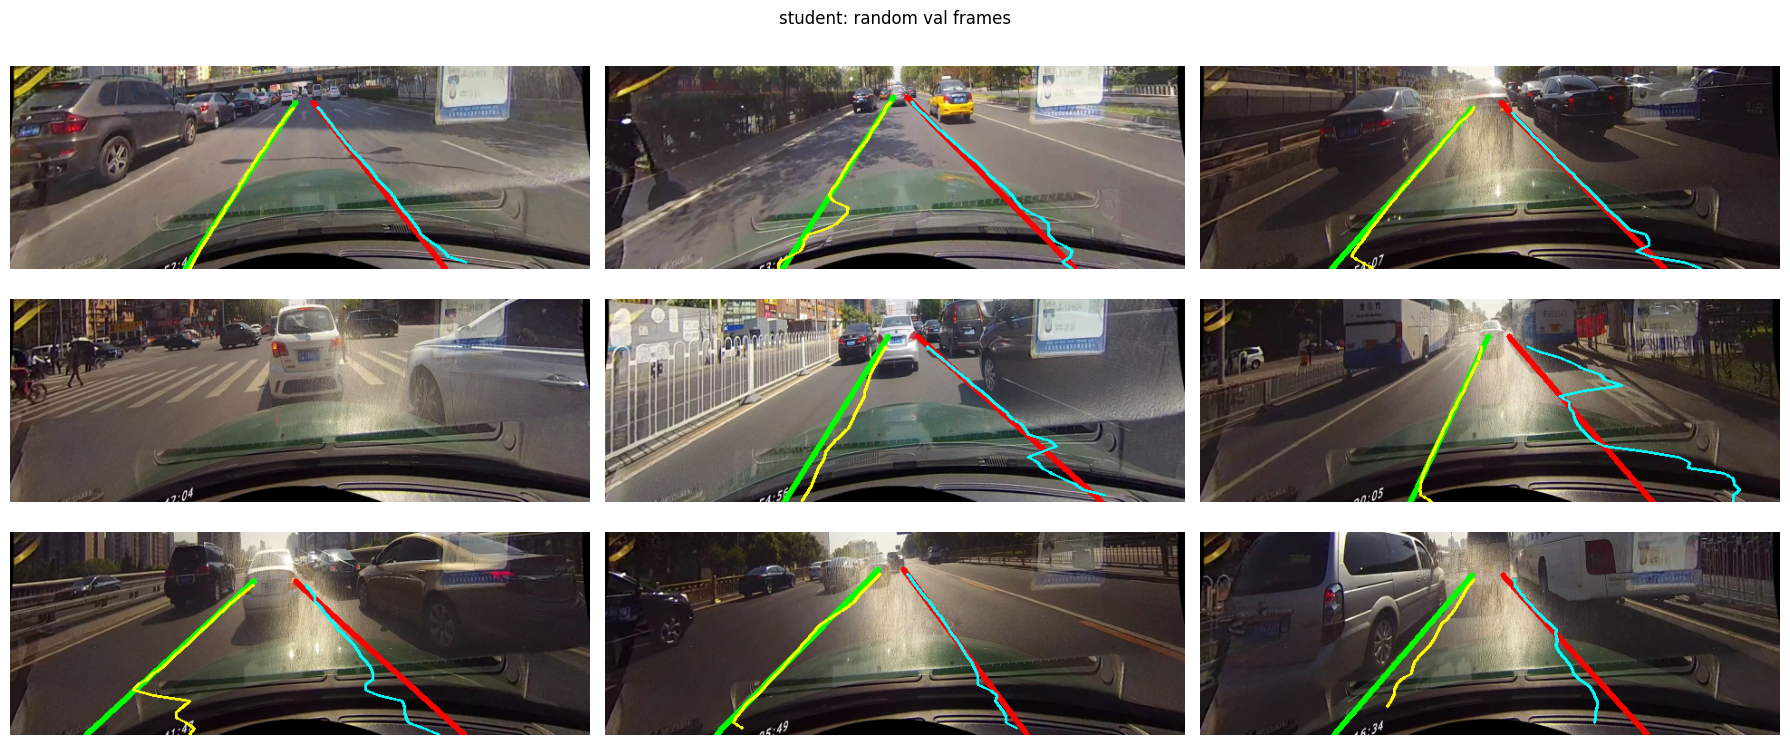

In [18]:
summary = pd.read_csv(RESULTS_CSV)
display(summary[['run', 'backbone', 'mode', 'f1', 'f1@0.7', 'precision', 'recall', 'ms_per_frame', 'params', 'gflops']].round(4))

images_val, lanes_val, _ = load('val')
student_threshold = yaml.safe_load(open(f"{MODELS_DIR}/{STUDENT_RUN}/config.yaml"))['threshold']
pred_val, conf, sigma = to_lanes(predict_raw(student, 'val'), student_threshold)
idx = np.random.default_rng(SEED).choice(len(pred_val), 9, replace=False)
show_pred(images_val, lanes_val, pred_val[idx], idx, 'student: random val frames', f"{FIGURES_DIR}/{STUDENT_RUN}_random.png")

In [19]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()